# Netflix Titles: Dataset Overview
First look at the **raw** dataset (`netflix_titles.csv`), followed by the genre, release-year and country views the dashboard will be built on. Run all cells before saving so the outputs are kept.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display plots inside the notebook
%matplotlib inline
sns.set_theme(style="whitegrid")

## 1. Making a dataframe from the dataset

In [2]:
df = pd.read_csv("../data/netflix_titles.csv")

## 2. Glance at the first few entries

In [3]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 3. Shape and column names

In [4]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))

Shape: (8807, 12)
Columns: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


## 4. Summary of the dataset

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.9 MB


## 5. Statistical summary for the entire dataframe

In [6]:
df.describe(include="all")

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


## 6. Checking the number of null values

In [7]:
nulls = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2),
}).sort_values("Missing", ascending=False)
nulls

,Missing,Missing %
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


## 7. Checking for duplicates
`show_id` is unique, so also check `title + type + release_year`.

In [8]:
print("Full-row duplicates:        ", df.duplicated().sum())
print("title/type/year duplicates: ", df.duplicated(subset=["title", "type", "release_year"]).sum())

Full-row duplicates:         0
title/type/year duplicates:  0


## 8. Content type split

In [9]:
print(df["type"].unique())
df["type"].value_counts()

<ArrowStringArray>
['Movie', 'TV Show']
Length: 2, dtype: str


type
Movie      6131
TV Show    2676
Name: count, dtype: int64

## 9. Rating counts
Some rows contain a duration such as `74 min` in `rating`. This is a data-entry error in the source file. The cleaning notebook moves these values back into `duration`.

In [10]:
df["rating"].value_counts()

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64

In [11]:
df[df["rating"].str.contains("min", na=False)][["show_id", "title", "rating", "duration"]]

,show_id,title,rating,duration
5541,s5542,Louis C.K. 2017,74 min,NaN
5794,s5795,Louis C.K.: Hilarious,84 min,NaN
5813,s5814,Louis C.K.: Live at the Comedy Store,66 min,NaN


## 10. Data types, missing values and unique values per column

In [12]:
summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique()
})
summary

,Data Type,Missing Values,Unique Values
show_id,str,0,8807
type,str,0,2
title,str,0,8807
director,str,2634,4528
cast,str,825,7692
country,str,831,748
date_added,str,10,1767
release_year,int64,0,74
rating,str,4,17
duration,str,3,220


## 11. Multi-value columns
`country`, `listed_in`, `cast` and `director` hold comma-separated lists, so a plain `value_counts()` treats `"United States, India"` as its own category. The counts below show the difference.

In [13]:
print("Raw top 5 countries (misleading):")
print(df["country"].value_counts().head(5))

Raw top 5 countries (misleading):
country
United States     2818
India              972
United Kingdom     419
Japan              245
South Korea        199
Name: count, dtype: int64


In [14]:
def explode_column(frame, source_col, new_col):
    out = frame[["show_id", "type", "release_year", source_col]].dropna(subset=[source_col]).copy()
    out[new_col] = out[source_col].str.split(",")
    out = out.explode(new_col)
    out[new_col] = out[new_col].str.strip()
    return out[out[new_col] != ""].drop(columns=source_col)

genres = explode_column(df, "listed_in", "genre")
countries = explode_column(df, "country", "country_single")

print("Distinct genres:   ", genres["genre"].nunique())
print("Distinct countries:", countries["country_single"].nunique())

Distinct genres:    42
Distinct countries: 122


## 12. Top 10 countries (after splitting)

country_single
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


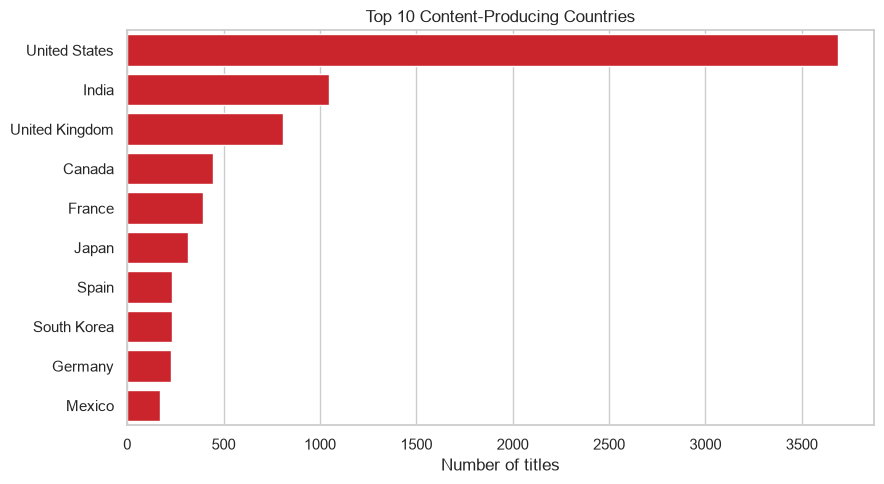

In [15]:
top_countries = countries["country_single"].value_counts().head(10)
print(top_countries)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_countries.values, y=top_countries.index, color="#E50914")
plt.title("Top 10 Content-Producing Countries")
plt.xlabel("Number of titles")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 13. Top 10 genres (after splitting)

genre
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


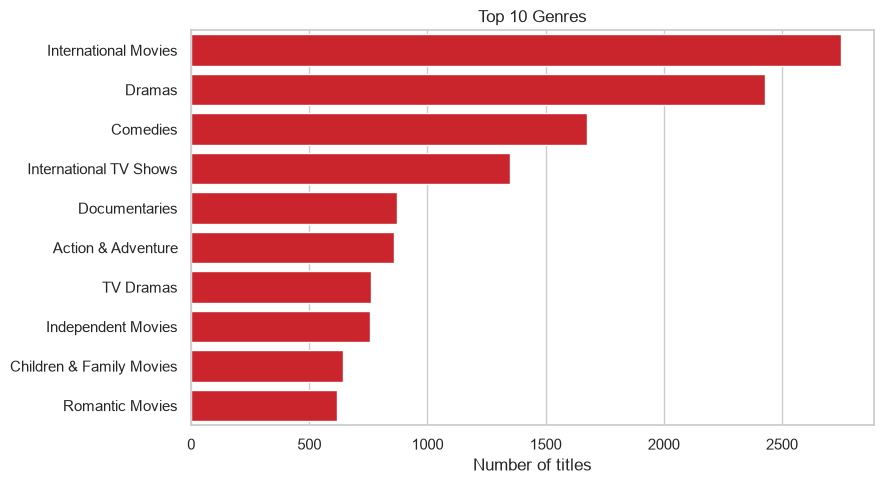

In [16]:
top_genres = genres["genre"].value_counts().head(10)
print(top_genres)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_genres.values, y=top_genres.index, color="#E50914")
plt.title("Top 10 Genres")
plt.xlabel("Number of titles")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 14. Release-year distribution

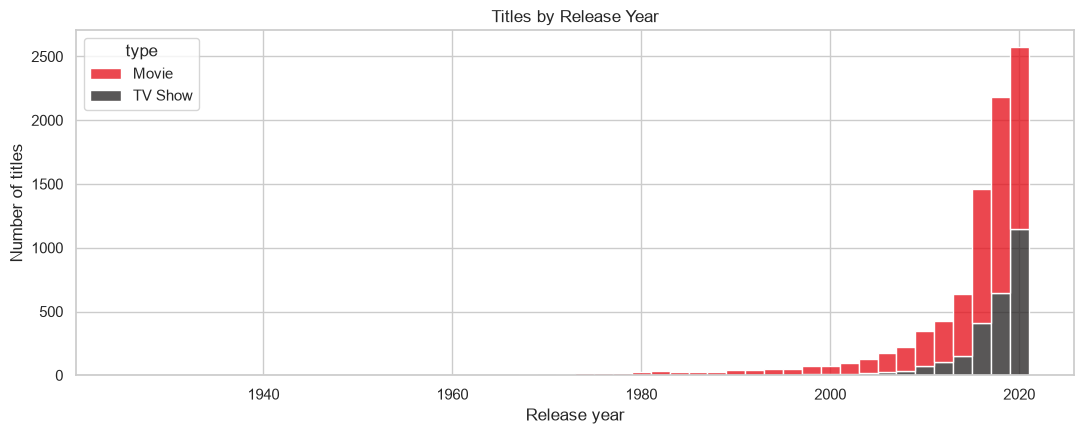

Release year range: 1925 to 2021
Share of titles released 2015 or later: 70.6 %


In [17]:
plt.figure(figsize=(11, 4.5))
sns.histplot(data=df, x="release_year", hue="type", multiple="stack", binwidth=2,
             palette={"Movie": "#E50914", "TV Show": "#221F1F"})
plt.title("Titles by Release Year")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.show()

print("Release year range:", df["release_year"].min(), "to", df["release_year"].max())
print("Share of titles released 2015 or later:", round((df["release_year"] >= 2015).mean() * 100, 1), "%")

## 15. Movies vs TV shows by release year (recent years)

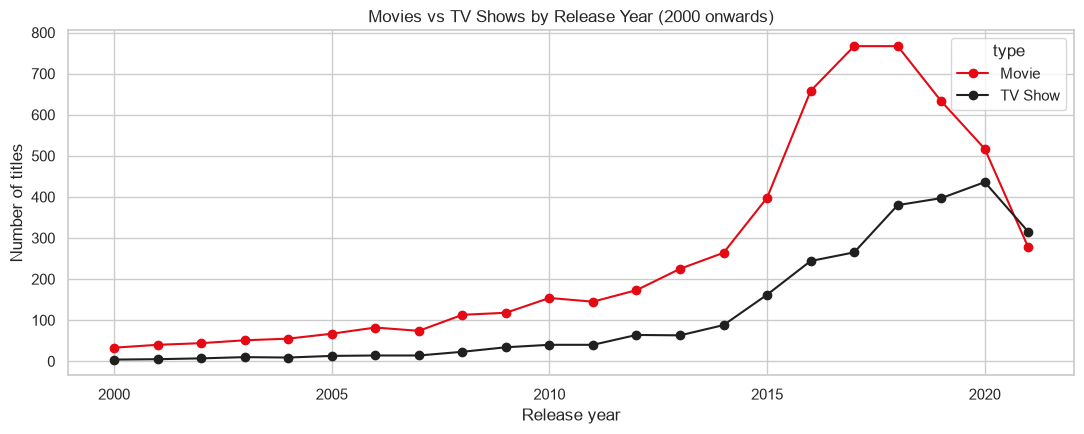

In [18]:
recent = df[df["release_year"] >= 2000].groupby(["release_year", "type"]).size().unstack(fill_value=0)

recent.plot(figsize=(11, 4.5), marker="o", color={"Movie": "#E50914", "TV Show": "#221F1F"})
plt.title("Movies vs TV Shows by Release Year (2000 onwards)")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.show()

## 16. Findings to carry into the dashboard
Fill these in after running the notebook:
- Content split between movies and TV shows:
- Top genres and countries:
- Years with the most releases:
- Data issues the cleaning notebook must handle: missing `director`, `country` and `cast`; duration stored in `rating`; multi-value columns